In [1]:
"""EDA Seattle 2016 : cibles = SiteEnergyUse(kBtu) et TotalGHGEmissions."""
import numpy as np                  # Le moteur de calcul
import pandas as pd                 # Le tableur intelligent
import seaborn as sns               # La visualition statistique
import matplotlib.pyplot as plt     # La personnalisation graphique

In [2]:
pd.set_option("display.width", 200, "display.max_columns", 50, "display.max_rows", 100)  # La configuration d'affichage
PATH = r"C:\Bam\Moi\DataCodes\Seattle\Brief_Seattle\Dataset\2016-building-energy-benchmarking-6af870b7ba821669818300.csv"  # Le chemin vers le fichier
TARGETS = ["SiteEnergyUse(kBtu)", "TotalGHGEmissions"]  # Les variables cibles à prédire
df = pd.read_csv(PATH)  # Le chargement des données
num = df.select_dtypes("number").columns.drop(["OSEBuildingID", "DataYear", "ZipCode", "CouncilDistrictCode"])  # Les colonnes numériques utiles
cat = df.select_dtypes(exclude="number").columns  # Les colonnes catégorielles (texte)


In [3]:
# 1. STRUCTURE : taille, types, doublons, cardinalité
print(df.shape, "| doublons lignes:", df.duplicated().sum(), "| doublons ID:", df.OSEBuildingID.duplicated().sum())
print(pd.DataFrame({"type": df.dtypes, "nuniques": df.nunique(), "%NaN": (df.isna().mean() * 100).round(1)})
      .sort_values("%NaN", ascending=False))

(3376, 46) | doublons lignes: 0 | doublons ID: 0
                                    type  nuniques   %NaN
Comments                         float64         0  100.0
Outlier                              str         2   99.1
YearsENERGYSTARCertified          object        65   96.5
ThirdLargestPropertyUseType          str        44   82.3
ThirdLargestPropertyUseTypeGFA   float64       501   82.3
SecondLargestPropertyUseType         str        50   50.3
SecondLargestPropertyUseTypeGFA  float64      1352   50.3
ENERGYSTARScore                  float64       100   25.0
LargestPropertyUseTypeGFA        float64      3122    0.6
LargestPropertyUseType               str        56    0.6
ZipCode                          float64        55    0.5
ListOfAllPropertyUseTypes            str       466    0.3
Electricity(kWh)                 float64      3352    0.3
SourceEUIWN(kBtu/sf)             float64      1694    0.3
GHGEmissionsIntensity            float64       511    0.3
TotalGHGEmissions      

In [4]:
# 2. ERREURS LOGIQUES (chaque ligne = une règle métier)
checks = {
    "cible <= 0": (df[TARGETS] <= 0).any(axis=1),
    "cible manquante": df[TARGETS].isna().any(axis=1),
    "0 étage": df.NumberofFloors == 0,
    "surface <= 0": df["PropertyGFATotal"] <= 0,
    "GFA total != parking + bâtiment": (df.PropertyGFATotal - df.PropertyGFAParking - df["PropertyGFABuilding(s)"]).abs() > 1,
    "énergie != élec + gaz + vapeur (>5%)": ((df[["Electricity(kBtu)", "NaturalGas(kBtu)", "SteamUse(kBtu)"]].sum(axis=1)
                                              - df["SiteEnergyUse(kBtu)"]).abs() > 0.05 * df["SiteEnergyUse(kBtu)"]),
    "année < 1850 ou > 2016": ~df.YearBuilt.between(1850, 2016),
    "ENERGYSTAR hors 1-100": ~df.ENERGYSTARScore.dropna().between(1, 100).reindex(df.index, fill_value=True),
    "Outlier signalé": df.Outlier.notna(),
    "ComplianceStatus != Compliant": df.ComplianceStatus != "Compliant",
    "DefaultData": df.DefaultData.fillna(False).astype(bool),
}
print(pd.Series({k: int(v.sum()) for k, v in checks.items()}, name="nb lignes concernées"))

cible <= 0                               21
cible manquante                           9
0 étage                                  16
surface <= 0                              0
GFA total != parking + bâtiment           0
énergie != élec + gaz + vapeur (>5%)     47
année < 1850 ou > 2016                    0
ENERGYSTAR hors 1-100                     0
Outlier signalé                          32
ComplianceStatus != Compliant           165
DefaultData                             113
Name: nb lignes concernées, dtype: int64


In [5]:
# 3. NUMÉRIQUES : stats, asymétrie, outliers IQR
q1, q3 = df[num].quantile(.25), df[num].quantile(.75)
iqr = q3 - q1
print(df[num].describe().T.assign(skew=df[num].skew(), outliers_IQR=((df[num] < q1 - 1.5 * iqr) | (df[num] > q3 + 1.5 * iqr)).sum()).round(2))

                                  count        mean          std        min        25%         50%         75%           max   skew  outliers_IQR
Latitude                         3376.0       47.62         0.05      47.50      47.60       47.62       47.66  4.773000e+01   0.14            16
Longitude                        3376.0     -122.33         0.03    -122.41    -122.35     -122.33     -122.32 -1.222200e+02  -0.14            92
YearBuilt                        3376.0     1968.57        33.09    1900.00    1948.00     1975.00     1997.00  2.015000e+03  -0.54             0
NumberofBuildings                3368.0        1.11         2.11       0.00       1.00        1.00        1.00  1.110000e+02  43.39           193
NumberofFloors                   3376.0        4.71         5.49       0.00       2.00        4.00        5.00  9.900000e+01   5.92           240
PropertyGFATotal                 3376.0    94833.54    218837.61   11285.00   28487.00    44175.00    90992.00  9.320156e+06

In [6]:
# 4. CATÉGORIELLES : modalités dominantes + moyenne des cibles par modalité
for c in ["BuildingType", "PrimaryPropertyType", "LargestPropertyUseType", "Neighborhood", "ComplianceStatus"]:
    print(f"\n--- {c} ---")
    print(df.groupby(c)[TARGETS].agg(["count", "median"]).sort_values((TARGETS[0], "count"), ascending=False).head(10).round(1))


--- BuildingType ---
                     SiteEnergyUse(kBtu)             TotalGHGEmissions       
                                   count      median             count median
BuildingType                                                                 
NonResidential                      1458   2598998.6              1458   47.1
Multifamily LR (1-4)                1015    975327.0              1011    9.4
Multifamily MR (5-9)                 580   2020444.6               580   35.5
Multifamily HR (10+)                 110   6743414.5               110  141.4
SPS-District K-12                     98   1987929.4                98   58.5
Nonresidential COS                    85   2796425.0                85   81.2
Campus                                24  17860150.0                24  339.5
Nonresidential WA                      1   3180819.2                 1   22.2

--- PrimaryPropertyType ---
                            SiteEnergyUse(kBtu)             TotalGHGEmissions       
      

In [7]:
# 5. CORRÉLATIONS aux cibles (Spearman : robuste aux outliers) + paires redondantes
corr = df[num].corr(method="spearman")
print(corr[TARGETS].drop(TARGETS).assign(abs_max=lambda d: d.abs().max(axis=1)).sort_values("abs_max", ascending=False).head(15).round(2))
pairs = corr.where(np.triu(np.ones(corr.shape, bool), 1)).stack()
print("Paires |rho| > 0.9 (multicolinéarité) :\n", pairs[pairs.abs() > .9].sort_values(ascending=False).round(2))

                                 SiteEnergyUse(kBtu)  TotalGHGEmissions  abs_max
SiteEnergyUseWN(kBtu)                           0.99               0.87     0.99
Electricity(kBtu)                               0.86               0.57     0.86
Electricity(kWh)                                0.86               0.57     0.86
NaturalGas(therms)                              0.57               0.83     0.83
NaturalGas(kBtu)                                0.57               0.83     0.83
GHGEmissionsIntensity                           0.56               0.82     0.82
PropertyGFATotal                                0.75               0.58     0.75
PropertyGFABuilding(s)                          0.74               0.57     0.74
LargestPropertyUseTypeGFA                       0.72               0.57     0.72
SiteEUI(kBtu/sf)                                0.71               0.71     0.71
SiteEUIWN(kBtu/sf)                              0.69               0.71     0.71
SourceEUI(kBtu/sf)          

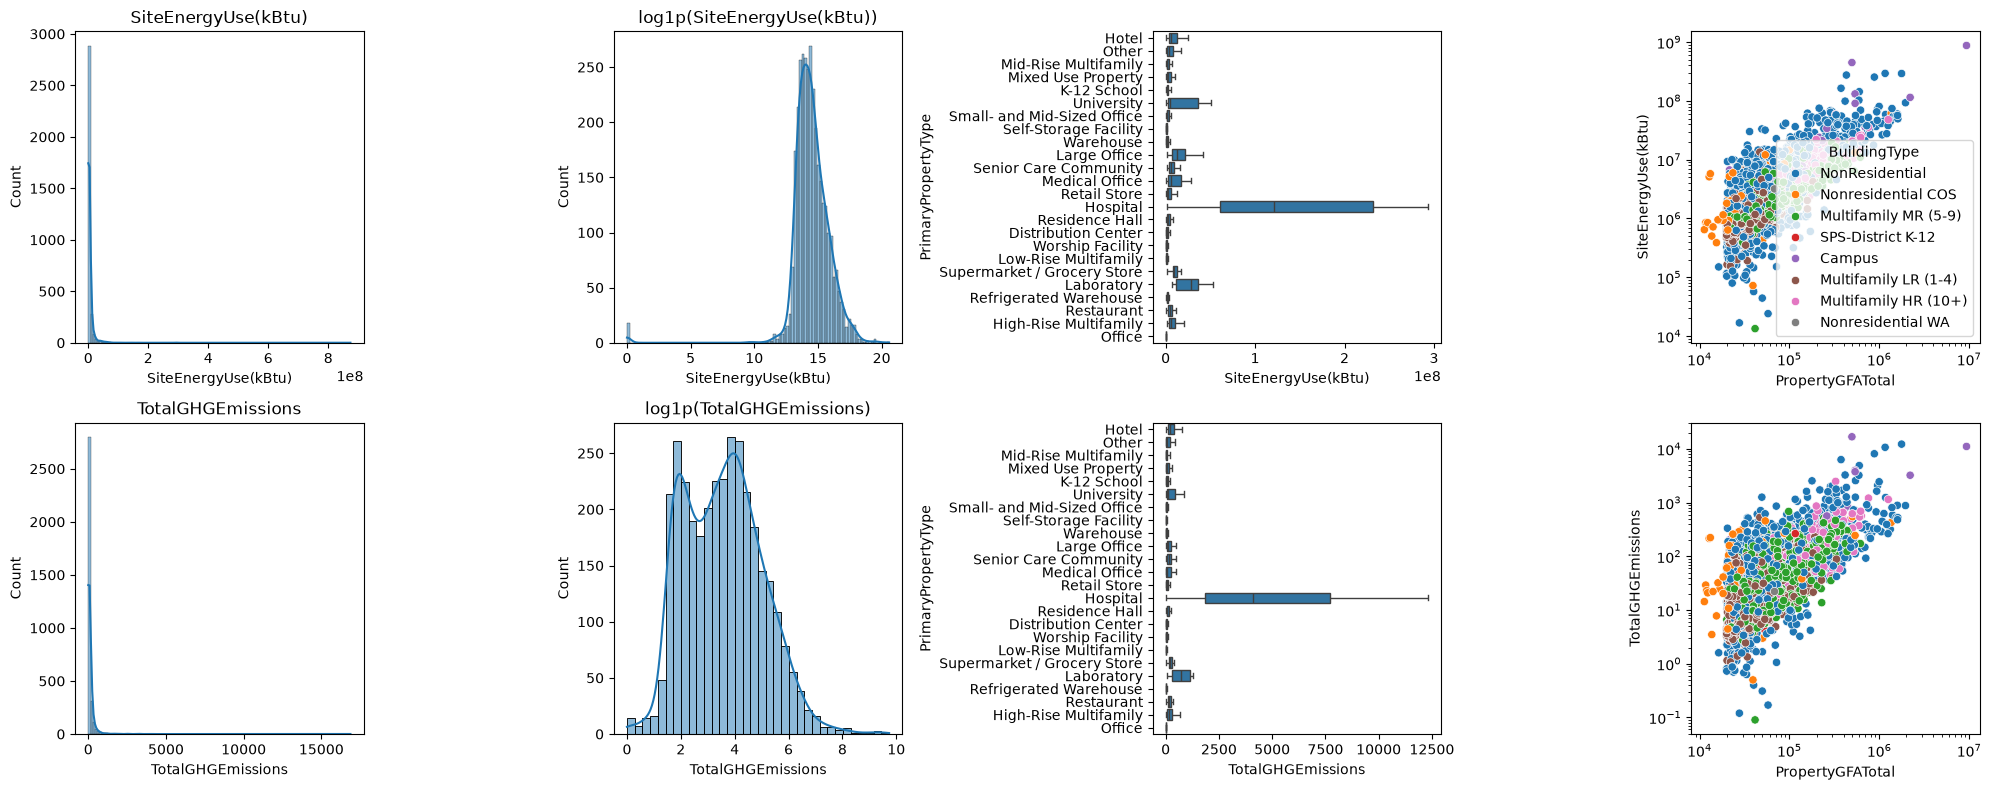

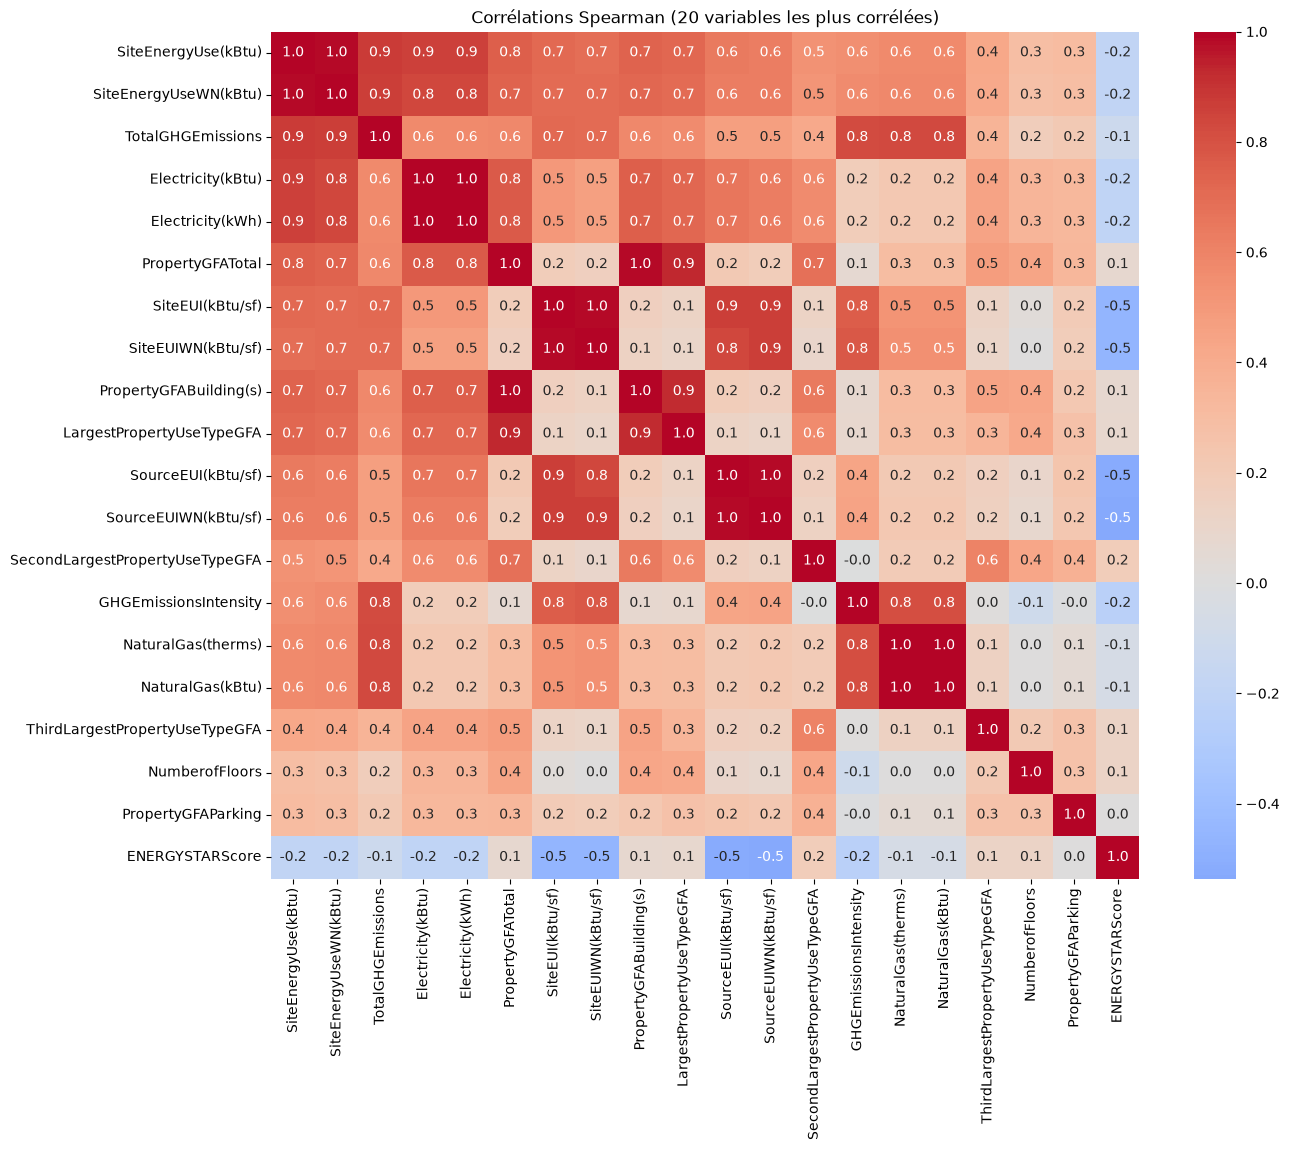

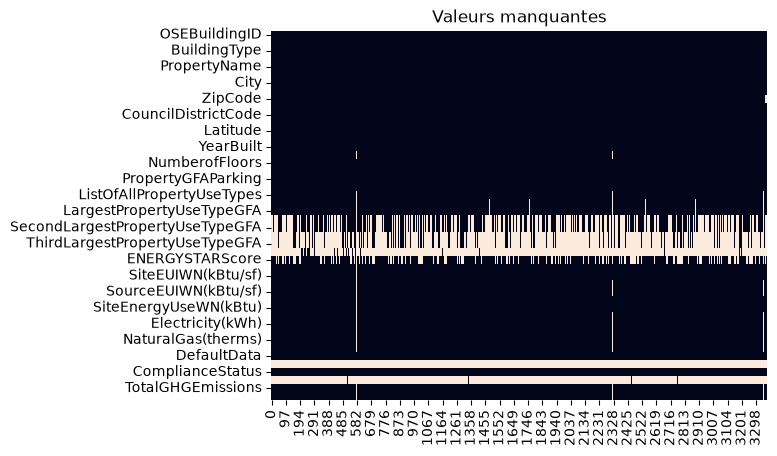

In [8]:
# 6. GRAPHIQUES : tout en 2 figures
fig, ax = plt.subplots(2, 4, figsize=(20, 8))
for i, t in enumerate(TARGETS):
    sns.histplot(df[t].dropna(), kde=True, ax=ax[i, 0]).set_title(t)
    sns.histplot(np.log1p(df[t].clip(lower=0).dropna()), kde=True, ax=ax[i, 1]).set_title(f"log1p({t})")
    sns.boxplot(data=df, y="PrimaryPropertyType", x=t, ax=ax[i, 2], showfliers=False)
    sns.scatterplot(data=df, x="PropertyGFATotal", y=t, hue="BuildingType", ax=ax[i, 3], legend=i == 0)
    ax[i, 3].set(xscale="log", yscale="log")
plt.tight_layout(); plt.show()

top = corr.abs().sum().nlargest(20).index
plt.figure(figsize=(14, 11))
sns.heatmap(corr.loc[top, top], annot=True, fmt=".1f", cmap="coolwarm", center=0)
plt.title("Corrélations Spearman (20 variables les plus corrélées)"); plt.show()
sns.heatmap(df.isna().T, cbar=False); plt.title("Valeurs manquantes"); plt.show()